# AI-Based Water Quality Monitoring and Potability Prediction System

Project Description

A comprehensive water quality monitoring system that uses machine learning to analyze key physicochemical parameters of water and predict whether the water is safe or unsafe for human consumption. The system processes water-quality measurements such as pH, hardness, dissolved solids, chloramines, sulfate, conductivity, organic carbon, trihalomethanes, and turbidity and provides an automated water-quality assessment.

Your dataset contains 3,276 samples and 10 columns, with Potability as the target:

- 0 → Not Potable / Unsafe Water: 1,998 samples
- 1 → Potable / Safe Water: 1,278 samples

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
DATA_PATH = Path("water_potability.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place water_potability.csv in the same folder as this notebook.")

print("Imports complete")

Imports complete


In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isna().sum())
print("\nTarget distribution:\n", df["Potability"].value_counts(dropna=False))

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0



Columns: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

Missing values:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Target distribution:
 Potability
0    1998
1    1278
Name: count, dtype: int64


In [3]:
# Validate target and features; never impute the target label.
if "Potability" not in df.columns:
    raise ValueError("Dataset must contain a Potability target column.")
df = df.dropna(subset=["Potability"]).copy()
if not set(df["Potability"].unique()).issubset({0, 1}):
    raise ValueError("Potability must be encoded as 0 (unsafe) and 1 (safe).")
df["Potability"] = df["Potability"].astype(int)
FEATURES = [c for c in df.columns if c != "Potability"]
X = df[FEATURES]
y = df["Potability"]
print("Rows after dropping missing target labels:", len(df))
print("Features:", FEATURES)
print("Target proportions:\n", y.value_counts(normalize=True).sort_index().rename(index={0:"Unsafe (0)",1:"Safe (1)"}))

Rows after dropping missing target labels: 3276
Features: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']
Target proportions:
 Potability
Unsafe (0)    0.60989
Safe (1)      0.39011
Name: proportion, dtype: float64


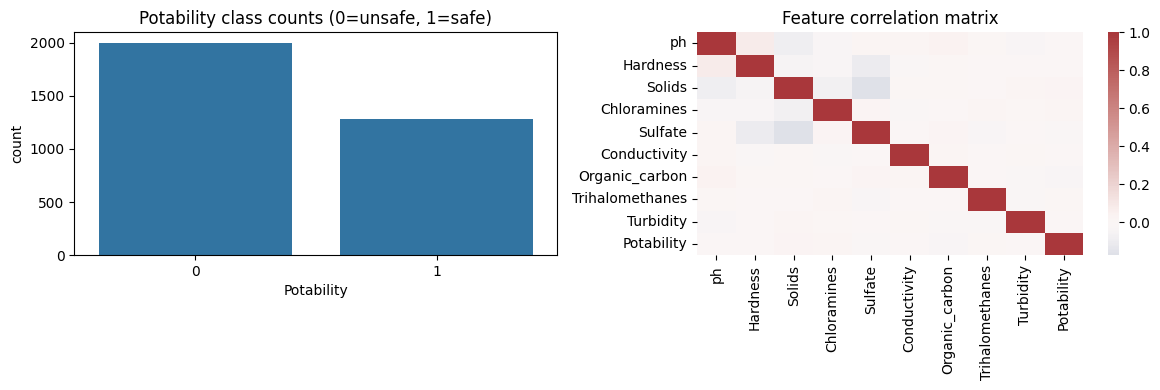

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000


In [4]:
# Exploratory data analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Potability", ax=axes[0])
axes[0].set_title("Potability class counts (0=unsafe, 1=safe)")
sns.heatmap(df.corr(numeric_only=True), cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()
display(df[FEATURES].describe().T)

In [5]:
# Split BEFORE imputation or any preprocessing. Test set is held out for final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), "Test rows:", len(X_test))
print("Train class fractions:\n", y_train.value_counts(normalize=True).sort_index())
print("Test class fractions:\n", y_test.value_counts(normalize=True).sort_index())

Train rows: 2620 Test rows: 656
Train class fractions:
 Potability
0    0.609924
1    0.390076
Name: proportion, dtype: float64
Test class fractions:
 Potability
0    0.609756
1    0.390244
Name: proportion, dtype: float64


In [6]:
# Baseline model: imputer is fitted within the training pipeline only.
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=4,
        min_samples_split=10, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
baseline.fit(X_train, y_train)

,steps,"[('imputer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,n_estimators,300


In [7]:
def evaluate_model(name, fitted_model, X_eval, y_eval):
    pred = fitted_model.predict(X_eval)
    prob = fitted_model.predict_proba(X_eval)[:, list(fitted_model.named_steps["model"].classes_).index(1)]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (safe)": precision_score(y_eval, pred, pos_label=1, zero_division=0),
        "Recall (safe)": recall_score(y_eval, pred, pos_label=1, zero_division=0),
        "Recall (unsafe)": recall_score(y_eval, pred, pos_label=0, zero_division=0),
        "F1 (safe)": f1_score(y_eval, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob),
    }

baseline_results = evaluate_model("Random Forest baseline", baseline, X_test, y_test)
display(pd.DataFrame([baseline_results]).round(4))
print(classification_report(y_test, baseline.predict(X_test), labels=[0,1],
                            target_names=["Unsafe (0)", "Safe (1)"], zero_division=0))

,Model,Accuracy,Precision (safe),Recall (safe),Recall (unsafe),F1 (safe),ROC-AUC
0,Random Forest baseline,0.6738,0.6082,0.4609,0.81,0.5244,0.6771


              precision    recall  f1-score   support

  Unsafe (0)       0.70      0.81      0.75       400
    Safe (1)       0.61      0.46      0.52       256

    accuracy                           0.67       656
   macro avg       0.65      0.64      0.64       656
weighted avg       0.66      0.67      0.66       656



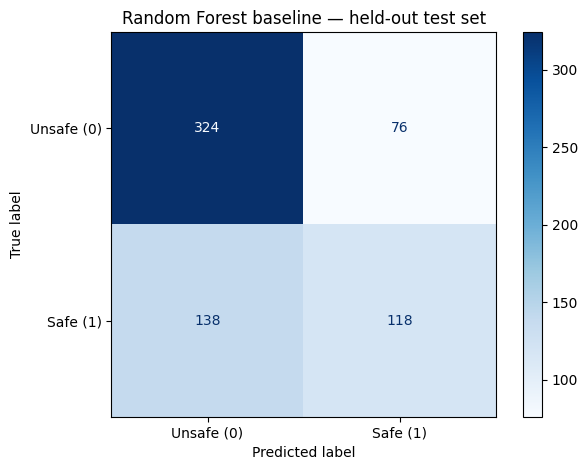

In [8]:
# Confusion matrix: rows are true labels, columns are predicted labels.
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline.predict(X_test), labels=[0,1],
    display_labels=["Unsafe (0)", "Safe (1)"], cmap="Blues", values_format="d"
)
plt.title("Random Forest baseline — held-out test set")
plt.tight_layout()
plt.show()

In [9]:
# Optional hyperparameter tuning: optimize ROC-AUC on training folds only.
# The test set is not used by RandomizedSearchCV. This may take a few minutes.
param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [8, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
    "model__class_weight": [None, "balanced"],
}
tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    tuning_pipeline, param_distributions=param_distributions, n_iter=12,
    scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Best mean CV ROC-AUC:", round(search.best_score_, 4))
best_model = search.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best mean CV ROC-AUC: 0.6969


,Model,Accuracy,Precision (safe),Recall (safe),Recall (unsafe),F1 (safe),ROC-AUC
0,Random Forest baseline,0.6738,0.6082,0.4609,0.81,0.5244,0.6771
1,Tuned Random Forest,0.6677,0.6092,0.4141,0.83,0.4930,0.6625


              precision    recall  f1-score   support

  Unsafe (0)       0.69      0.83      0.75       400
    Safe (1)       0.61      0.41      0.49       256

    accuracy                           0.67       656
   macro avg       0.65      0.62      0.62       656
weighted avg       0.66      0.67      0.65       656



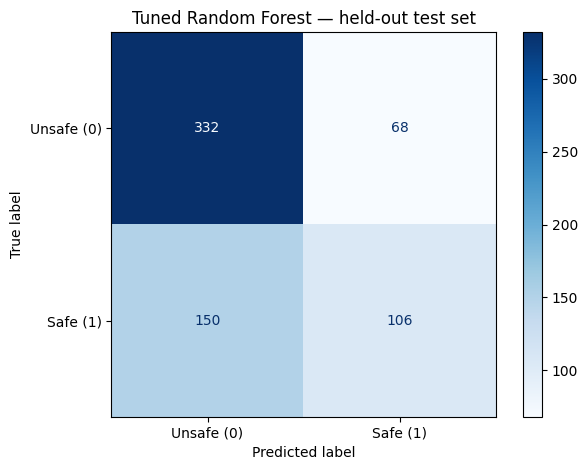

In [10]:
# Evaluate the tuned model once on the held-out test set.
tuned_results = evaluate_model("Tuned Random Forest", best_model, X_test, y_test)
comparison = pd.DataFrame([baseline_results, tuned_results])
display(comparison.sort_values("ROC-AUC", ascending=False).round(4))
print(classification_report(y_test, best_model.predict(X_test), labels=[0,1],
                            target_names=["Unsafe (0)", "Safe (1)"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_model.predict(X_test), labels=[0,1],
    display_labels=["Unsafe (0)", "Safe (1)"], cmap="Blues", values_format="d"
)
plt.title("Tuned Random Forest — held-out test set")
plt.tight_layout()
plt.show()

,Feature,Importance
0,ph,0.147529
4,Sulfate,0.131761
1,Hardness,0.127088
3,Chloramines,0.122604
2,Solids,0.112021
5,Conductivity,0.097023
8,Turbidity,0.088646
6,Organic_carbon,0.087801
7,Trihalomethanes,0.085526


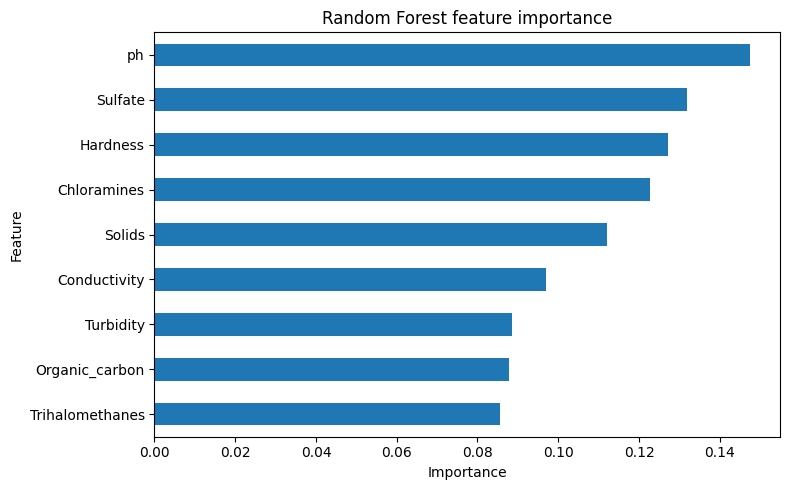

In [11]:
# Feature importance from the fitted model (descriptive, not causal).
model_step = best_model.named_steps["model"]
importance = pd.DataFrame({"Feature": FEATURES, "Importance": model_step.feature_importances_})
importance = importance.sort_values("Importance", ascending=False)
display(importance)
ax = importance.sort_values("Importance").plot.barh(x="Feature", y="Importance", legend=False, figsize=(8,5))
ax.set_title("Random Forest feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

# Step 13: Evaluate both models
Accuracy is the percentage of correct predictions, but it does not tell the whole story.
Metric	What it tells you
- Accuracy	Overall proportion of correct predictions
- Precision	How often predictions for the selected positive class are correct
- Recall	How many actual examples of the selected class are detected
- F1 score	Balance between precision and recall
- ROC-AUC	How well the model ranks examples from the two classes across thresholds
For your water-quality project, pay special attention to unsafe-water recall. Because 0 represents the unsafe class, calculate it with:

In [12]:
# Save a deployable model trained on all labeled rows after evaluation.
# The reported test metrics above remain from the untouched hold-out split.
final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        **{k.replace("model__", ""): v for k, v in search.best_params_.items()},
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
final_pipeline.fit(X, y)
OUT = Path(".")
joblib.dump(final_pipeline, OUT / "water_potability_model.joblib")
metrics = evaluate_model("Tuned Random Forest", best_model, X_test, y_test)
metrics_json = {
    "accuracy": float(metrics["Accuracy"]),
    "precision_safe": float(metrics["Precision (safe)"]),
    "recall_safe": float(metrics["Recall (safe)"]),
    "recall_unsafe": float(metrics["Recall (unsafe)"]),
    "f1_safe": float(metrics["F1 (safe)"]),
    "roc_auc": float(metrics["ROC-AUC"]),
    "confusion_matrix_labels_0_unsafe_1_safe": confusion_matrix(y_test, best_model.predict(X_test), labels=[0,1]).tolist(),
    "features": FEATURES, "training_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "model_note": "Held-out split baseline; not independent field validation."
}
(OUT / "evaluation_metrics.json").write_text(json.dumps(metrics_json, indent=2), encoding="utf-8")
print("Saved model and evaluation metrics to", OUT.resolve())

Saved model and evaluation metrics to D:\1. Job\Project worked on\-AI-Smart-Water-Quality-Monitoring-System\AI Water (Portable + Safe ) Quality Monitoring


In [13]:
from pathlib import Path
import json
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

print("Imports ready")
print("Files will be saved in:", Path.cwd())

Imports ready
Files will be saved in: d:\1. Job\Project worked on\-AI-Smart-Water-Quality-Monitoring-System\AI Water (Portable + Safe ) Quality Monitoring


In [14]:
from pathlib import Path

for filename in [
    "water_potability_model.joblib",
    "evaluation_metrics.json"
]:
    path = Path(filename)
    print(filename, "exists:", path.exists())

water_potability_model.joblib exists: True
evaluation_metrics.json exists: True


# Step 15: Save the final model
Once you have chosen the model, save the complete pipeline rather than only the classifier.

In [15]:
import joblib

model = joblib.load("water_potability_model.joblib")

# Part D. Build the Streamlit application
Step 16: Understand how the app works
The application connects user inputs to the trained model.
1. User enters water parameters
Nine measurements through the web form

2. Input validation and preprocessing
Check values and apply the saved pipeline

3. Machine-learning prediction
The selected model predicts class 0 or class 1

4. Results displayed
Prediction, screening score and recommendations

# — Build an Interactive Dashboard


# Step 17: Understand the Streamlit interface
Open the app source:
Open app.py
The app should use the same nine feature names and ordering as the model. Conceptually, its input code will resemble this:

In [25]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: streamlit in c:\python310\lib\site-packages (1.63.0)




[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
!streamlit --version

Streamlit, version 1.63.0


In [29]:
import streamlit as st

In [31]:
%%writefile app.py

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

# ---------------------------------------------------------------------
# Configuration and files
# Keep app.py, the model, optional dataset, and metrics JSON together.
# ---------------------------------------------------------------------
BASE = Path(__file__).resolve().parent
MODEL_PATH = BASE / "water_potability_model.joblib"
METRICS_PATH = BASE / "evaluation_metrics.json"
DATA_PATH = BASE / "water_potability.csv"

FEATURES = [
    "ph", "Hardness", "Solids", "Chloramines", "Sulfate",
    "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"
]
FRIENDLY_NAMES = {
    "ph": "pH",
    "Hardness": "Hardness",
    "Solids": "Total dissolved solids",
    "Chloramines": "Chloramines",
    "Sulfate": "Sulfate",
    "Conductivity": "Conductivity",
    "Organic_carbon": "Organic carbon",
    "Trihalomethanes": "Trihalomethanes",
    "Turbidity": "Turbidity",
}
UNITS = {
    "ph": "pH units",
    "Hardness": "mg/L as CaCO₃ (verify dataset units)",
    "Solids": "dataset units (often mg/L)",
    "Chloramines": "dataset units (often mg/L)",
    "Sulfate": "dataset units (often mg/L)",
    "Conductivity": "dataset units (often µS/cm)",
    "Organic_carbon": "dataset units",
    "Trihalomethanes": "verify source units",
    "Turbidity": "dataset units (often NTU)",
}

st.set_page_config(
    page_title="AquaInsight | Water Quality AI",
    page_icon="💧",
    layout="wide",
    initial_sidebar_state="expanded",
)

# ---------------------------------------------------------------------
# Styling
# ---------------------------------------------------------------------
st.markdown(
    """
    <style>
      @import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Manrope:wght@500;600;700;800&display=swap');
      html, body, [class*="css"] { font-family: 'DM Sans', sans-serif; }
      .stApp { background: linear-gradient(180deg, #f4fbfc 0%, #f7fafc 42%, #f7f9fc 100%); }
      .block-container { padding-top: 1.4rem; padding-bottom: 2.5rem; max-width: 1500px; }
      h1, h2, h3 { font-family: 'Manrope', sans-serif; color: #123047; }
      .hero {
        padding: 1.45rem 1.7rem; border-radius: 22px;
        background: linear-gradient(115deg, #092e43 0%, #087e8b 58%, #28a7a1 100%);
        color: white; margin-bottom: 1.1rem;
        box-shadow: 0 12px 30px rgba(12, 75, 94, .16);
      }
      .hero h1 { color: white; font-size: 2.1rem; margin: 0 0 .3rem 0; }
      .hero p { color: #e0f7f7; margin: 0; font-size: 1rem; }
      .section-kicker { color: #087e8b; text-transform: uppercase; letter-spacing: .12em;
        font-weight: 700; font-size: .75rem; margin-bottom: .25rem; }
      .note-card {
        border: 1px solid #d9e9ed; background: rgba(255,255,255,.88);
        padding: 1rem 1.1rem; border-radius: 16px; height: 100%;
      }
      .small-muted { color: #617889; font-size: .88rem; }
      [data-testid="stMetric"] {
        background: white; border: 1px solid #dce9ed; padding: 1rem 1.1rem;
        border-radius: 16px; box-shadow: 0 3px 12px rgba(17, 68, 84, .04);
      }
      div.stButton > button[kind="primary"], div.stFormSubmitButton > button[kind="primary"] {
        background: linear-gradient(100deg, #087e8b, #20a39e); border: 0; border-radius: 10px;
        font-weight: 700; min-height: 2.8rem;
      }
      div[data-testid="stSidebar"] { background: #edf7f8; }
      .stAlert { border-radius: 12px; }
      footer { visibility: hidden; }
    </style>
    """,
    unsafe_allow_html=True,
)

# ---------------------------------------------------------------------
# Cached resource loaders
# ---------------------------------------------------------------------
@st.cache_resource
def load_model():
    if not MODEL_PATH.exists():
        return None
    return joblib.load(MODEL_PATH)

@st.cache_data
def load_metrics():
    if not METRICS_PATH.exists():
        return None
    try:
        return json.loads(METRICS_PATH.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        return None

@st.cache_data
def load_dataset():
    if not DATA_PATH.exists():
        return None
    try:
        df = pd.read_csv(DATA_PATH)
        if "Potability" in df.columns:
            df = df.dropna(subset=["Potability"]).copy()
        return df
    except Exception:
        return None

model = load_model()
metrics = load_metrics()
dataset = load_dataset()

# ---------------------------------------------------------------------
# Header and navigation
# ---------------------------------------------------------------------
st.markdown(
    """
    <div class="hero">
      <div class="section-kicker" style="color:#b7f0eb;">ENVIRONMENTAL INTELLIGENCE · ML DEMO</div>
      <h1>💧 AquaInsight</h1>
      <p>AI-assisted water quality screening · Explore measurements, test a sample, and review model performance.</p>
    </div>
    """,
    unsafe_allow_html=True,
)

with st.sidebar:
    st.markdown("## 💧 AquaInsight")
    st.caption("Water quality intelligence")
    page = st.radio(
        "Navigate",
        ["Overview", "Predict a sample", "Explore dataset", "Model performance", "About & limitations"],
        label_visibility="collapsed",
    )
    st.divider()
    st.markdown("**Project status**")
    st.write("Model file:", "✅ found" if MODEL_PATH.exists() else "⚠️ missing")
    st.write("Dataset:", "✅ found" if dataset is not None else "Not found")
    st.write("Evaluation metrics:", "✅ found" if metrics else "Not found")
    st.caption("Keep the model, optional CSV, and metrics JSON beside app.py.")

if model is None:
    st.error(
        f"Model file not found: `{MODEL_PATH.name}`. Place the trained model beside `app.py`, "
        "or update MODEL_PATH in this file to match your actual filename."
    )
    st.info("The dashboard can be inspected after the model file is placed in the project folder.")
    st.stop()

# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------
def screening_score(values):
    """Illustrative equal-weight checks; this is not a validated WQI."""
    checks = {
        "pH between 6.5 and 8.5 (illustrative)": 6.5 <= values["ph"] <= 8.5,
        "Solids ≤ 500 (unit must be verified)": values["Solids"] <= 500,
        "Chloramines ≤ 4 (unit must be verified)": values["Chloramines"] <= 4,
        "Sulfate ≤ 250 (unit must be verified)": values["Sulfate"] <= 250,
        "Trihalomethanes ≤ 80 (unit must be verified)": values["Trihalomethanes"] <= 80,
        "Turbidity ≤ 5 (unit must be verified)": values["Turbidity"] <= 5,
    }
    score = round(100 * sum(checks.values()) / len(checks))
    return score, checks

def predict_sample(values):
    row = pd.DataFrame([values], columns=FEATURES)
    pred = int(model.predict(row)[0])
    safe_prob, unsafe_prob = np.nan, np.nan
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(row)[0]
        classes = list(getattr(model, "classes_", []))
        if not classes and hasattr(model, "named_steps"):
            last_step = list(model.named_steps.values())[-1]
            classes = list(getattr(last_step, "classes_", []))
        if 1 in classes:
            safe_prob = float(probs[classes.index(1)])
        if 0 in classes:
            unsafe_prob = float(probs[classes.index(0)])
    return pred, safe_prob, unsafe_prob

def add_metric_card(label, value, help_text=None):
    st.metric(label, value, help=help_text)

def make_gauge(value, title, suffix=""):
    fig = go.Figure(go.Indicator(
        mode="gauge+number",
        value=float(value),
        number={"suffix": suffix, "font": {"size": 30, "color": "#123047"}},
        title={"text": title, "font": {"size": 15, "color": "#466274"}},
        gauge={
            "axis": {"range": [0, 100], "tickwidth": 1, "tickcolor": "#78909c"},
            "bar": {"color": "#0b8f95"},
            "bgcolor": "white",
            "borderwidth": 1,
            "bordercolor": "#d9e9ed",
            "steps": [
                {"range": [0, 40], "color": "#fce8e6"},
                {"range": [40, 70], "color": "#fff3d6"},
                {"range": [70, 100], "color": "#dff5ee"},
            ],
        },
    ))
    fig.update_layout(height=245, margin=dict(l=18, r=18, t=55, b=8), paper_bgcolor="rgba(0,0,0,0)")
    return fig

# ---------------------------------------------------------------------
# Overview
# ---------------------------------------------------------------------
if page == "Overview":
    st.markdown('<div class="section-kicker">Overview</div>', unsafe_allow_html=True)
    st.header("Water quality at a glance")
    st.write("A compact workspace for model-assisted screening and exploratory analysis.")

    if dataset is not None:
        total_rows = len(dataset)
        target_rate = dataset["Potability"].mean() * 100 if "Potability" in dataset else np.nan
        feature_count = len([c for c in FEATURES if c in dataset.columns])
        missing_count = int(dataset[FEATURES].isna().sum().sum()) if all(c in dataset for c in FEATURES) else 0
    else:
        total_rows, target_rate, feature_count, missing_count = 0, np.nan, len(FEATURES), 0

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Dataset samples", f"{total_rows:,}" if dataset is not None else "Not loaded")
    c2.metric("Input parameters", feature_count)
    c3.metric("Missing feature values", f"{missing_count:,}" if dataset is not None else "—")
    c4.metric("Potable-labelled samples", f"{target_rate:.1f}%" if not np.isnan(target_rate) else "—")
    st.caption("Dataset statistics describe the local benchmark CSV, if available; they do not describe live sensor feeds.")

    left, right = st.columns([1.25, 1])
    with left:
        st.markdown("### How the system works")
        flow = go.Figure()
        flow.add_trace(go.Scatter(
            x=[0.5, 1.5, 2.5, 3.5], y=[0.5, 0.5, 0.5, 0.5],
            mode="markers+text",
            marker=dict(size=58, color=["#0b7180", "#159a9c", "#3aaea3", "#123047"]),
            text=["Input<br>measurements", "Preprocess<br>features", "ML model<br>prediction", "Guidance<br>& review"],
            textposition="bottom center",
            textfont=dict(size=12, color="#123047"),
            hoverinfo="skip",
        ))
        for x in [1, 2, 3]:
            flow.add_annotation(x=x, y=0.5, ax=x-0.38, ay=0.5, axref="x", ayref="y",
                                xref="x", yref="y", text="", showarrow=True,
                                arrowhead=3, arrowsize=1.3, arrowwidth=2, arrowcolor="#9ab9c0")
        flow.update_layout(
            height=245, xaxis=dict(visible=False, range=[0, 4]), yaxis=dict(visible=False, range=[0, 1.15]),
            margin=dict(l=5, r=5, t=12, b=42), paper_bgcolor="rgba(0,0,0,0)",
            plot_bgcolor="rgba(0,0,0,0)", showlegend=False,
        )
        st.plotly_chart(flow, use_container_width=True, config={"displayModeBar": False})
    with right:
        st.markdown("### Start here")
        st.markdown(
            """
            <div class="note-card">
              <h4>🧪 Predict a sample</h4>
              Enter the nine model features and receive a class prediction, estimated class probabilities (if supported), and an illustrative parameter-screening score.
              <hr>
              <h4>📊 Explore the dataset</h4>
              Review class balance, distributions, missing values, and correlations when the CSV is available.
              <hr>
              <h4>🧭 Review model performance</h4>
              Inspect held-out benchmark metrics and remember that field validation is still required.
            </div>
            """,
            unsafe_allow_html=True,
        )
    st.warning("Screening demonstration only. A model prediction or illustrative score cannot confirm drinking-water safety. Use qualified laboratory testing and applicable standards.")

# ---------------------------------------------------------------------
# Prediction page
# ---------------------------------------------------------------------
elif page == "Predict a sample":
    st.markdown('<div class="section-kicker">Interactive laboratory</div>', unsafe_allow_html=True)
    st.header("Predict a water sample")
    st.write("Enter measurements in the units used by your source data. Confirm units before interpreting any threshold or recommendation.")

    with st.form("water_parameters"):
        st.markdown("#### Physicochemical parameters")
        c1, c2, c3 = st.columns(3)
        with c1:
            ph = st.number_input("pH", min_value=0.0, max_value=14.0, value=7.0, step=0.1, help="Dimensionless.")
            hardness = st.number_input("Hardness", min_value=0.0, value=150.0, step=1.0, help=UNITS["Hardness"])
            solids = st.number_input("Solids / TDS", min_value=0.0, value=500.0, step=10.0, help=UNITS["Solids"])
        with c2:
            chloramines = st.number_input("Chloramines", min_value=0.0, value=3.0, step=0.1, help=UNITS["Chloramines"])
            sulfate = st.number_input("Sulfate", min_value=0.0, value=250.0, step=5.0, help=UNITS["Sulfate"])
            conductivity = st.number_input("Conductivity", min_value=0.0, value=400.0, step=10.0, help=UNITS["Conductivity"])
        with c3:
            organic_carbon = st.number_input("Organic carbon", min_value=0.0, value=10.0, step=0.5, help=UNITS["Organic_carbon"])
            trihalomethanes = st.number_input("Trihalomethanes", min_value=0.0, value=50.0, step=1.0, help=UNITS["Trihalomethanes"])
            turbidity = st.number_input("Turbidity", min_value=0.0, value=2.0, step=0.1, help=UNITS["Turbidity"])
        submitted = st.form_submit_button("💧 Analyse sample", type="primary", use_container_width=True)

    if submitted:
        values = {
            "ph": ph, "Hardness": hardness, "Solids": solids,
            "Chloramines": chloramines, "Sulfate": sulfate,
            "Conductivity": conductivity, "Organic_carbon": organic_carbon,
            "Trihalomethanes": trihalomethanes, "Turbidity": turbidity,
        }
        try:
            prediction, safe_prob, unsafe_prob = predict_sample(values)
            score, checks = screening_score(values)
        except Exception as exc:
            st.error(f"Prediction failed: {exc}")
            st.stop()

        st.divider()
        st.markdown("### Results")
        r1, r2, r3 = st.columns([1.1, 1, 1])
        with r1:
            if prediction == 1:
                st.success("### Model class: POTABLE (1)")
            else:
                st.error("### Model class: NON-POTABLE (0)")
            st.caption("This is a prediction of the dataset label, not a safety certification.")
        with r2:
            st.metric("Illustrative screening score", f"{score}/100")
            st.caption("Equal-weight count of six simple checks; not a validated WQI.")
        with r3:
            st.metric("Estimated safe-class probability", f"{safe_prob:.1%}" if not np.isnan(safe_prob) else "Unavailable")
            st.caption("Probability may not be calibrated for real-world samples.")

        g1, g2 = st.columns(2)
        with g1:
            st.plotly_chart(make_gauge(score, "Parameter screening score", "/100"), use_container_width=True, config={"displayModeBar": False})
        with g2:
            probability_value = safe_prob * 100 if not np.isnan(safe_prob) else 0
            st.plotly_chart(make_gauge(probability_value, "Model estimated safe-class probability", "%"), use_container_width=True, config={"displayModeBar": False})

        st.markdown("### Parameter profile")
        profile = pd.DataFrame({
            "Parameter": [FRIENDLY_NAMES[f] for f in FEATURES],
            "Entered value": [values[f] for f in FEATURES],
            "Feature": FEATURES,
        })
        bar = px.bar(
            profile, x="Parameter", y="Entered value", color="Parameter",
            title="Entered measurements (different units; compare values cautiously)",
            hover_data={"Feature": True, "Entered value": ":.3f"},
        )
        bar.update_layout(showlegend=False, xaxis_tickangle=-25, height=390, margin=dict(l=10, r=10, t=55, b=90))
        st.plotly_chart(bar, use_container_width=True)

        st.markdown("### Screening checks")
        check_df = pd.DataFrame([{"Check": k, "Result": "Pass" if v else "Review"} for k, v in checks.items()])
        st.dataframe(check_df, use_container_width=True, hide_index=True)
        if prediction == 0:
            st.error("The model classified this sample as non-potable. Do not rely on it as safe for drinking; seek confirmatory laboratory testing and follow local public-health guidance.")
        else:
            st.info("The model classified this sample as potable, but this does not prove safety. Confirm microbiological and chemical safety through an accredited laboratory.")
        st.caption("The parameter checks are illustrative and depend on verifying the units and applicable local standards.")

        report = {
            "prediction_class": prediction,
            "prediction_label": "Potable class" if prediction == 1 else "Non-potable class",
            "safe_class_probability": None if np.isnan(safe_prob) else safe_prob,
            "unsafe_class_probability": None if np.isnan(unsafe_prob) else unsafe_prob,
            "illustrative_screening_score": score,
            "input_values": values,
            "illustrative_checks": checks,
            "note": "Research screening only; not a certified drinking-water assessment."
        }
        st.download_button(
            "⬇️ Download sample report (JSON)",
            data=json.dumps(report, indent=2),
            file_name="water_sample_screening_report.json",
            mime="application/json",
            use_container_width=True,
        )

# ---------------------------------------------------------------------
# Dataset exploration page
# ---------------------------------------------------------------------
elif page == "Explore dataset":
    st.markdown('<div class="section-kicker">Exploratory analysis</div>', unsafe_allow_html=True)
    st.header("Explore the benchmark dataset")
    if dataset is None:
        st.warning(f"Dataset not found at `{DATA_PATH}`. Put `water_potability.csv` beside app.py to enable these charts.")
    else:
        available = [c for c in FEATURES if c in dataset.columns]
        a, b, c = st.columns(3)
        a.metric("Rows", f"{len(dataset):,}")
        b.metric("Columns", len(dataset.columns))
        c.metric("Missing feature cells", f"{int(dataset[available].isna().sum().sum()):,}")
        tab1, tab2, tab3 = st.tabs(["Class balance", "Feature distributions", "Relationships"])
        with tab1:
            if "Potability" in dataset:
                class_df = dataset["Potability"].map({0: "Non-potable label (0)", 1: "Potable label (1)"}).value_counts().rename_axis("Class").reset_index(name="Samples")
                fig = px.pie(class_df, names="Class", values="Samples", hole=0.58, title="Potability labels in the dataset")
                fig.update_traces(textposition="inside", textinfo="percent+label")
                fig.update_layout(height=390)
                st.plotly_chart(fig, use_container_width=True)
                st.caption("Class distribution in the dataset is not a measure of real-world water safety prevalence.")
        with tab2:
            feature = st.selectbox("Choose a parameter", available, format_func=lambda x: FRIENDLY_NAMES.get(x, x))
            hist = px.histogram(dataset, x=feature, color="Potability" if "Potability" in dataset else None,
                                marginal="box", barmode="overlay", opacity=0.75,
                                title=f"Distribution of {FRIENDLY_NAMES.get(feature, feature)}")
            hist.update_layout(height=440, legend_title_text="Potability label")
            st.plotly_chart(hist, use_container_width=True)
        with tab3:
            numeric_cols = dataset[available].select_dtypes(include=np.number).columns.tolist()
            if len(numeric_cols) >= 2:
                corr = dataset[numeric_cols].corr(numeric_only=True)
                heat = px.imshow(corr, text_auto=".2f", aspect="auto", color_continuous_scale="RdBu_r",
                                 zmin=-1, zmax=1, title="Feature correlation heatmap")
                heat.update_layout(height=600)
                st.plotly_chart(heat, use_container_width=True)
            st.caption("Correlation indicates association, not causation.")
        with st.expander("View sample rows"):
            st.dataframe(dataset.head(100), use_container_width=True)
        with st.expander("Missing values by feature"):
            missing = dataset[available].isna().sum().sort_values(ascending=False).reset_index()
            missing.columns = ["Feature", "Missing values"]
            missing["Missing %"] = (missing["Missing values"] / len(dataset) * 100).round(2)
            fig = px.bar(missing, x="Feature", y="Missing values", hover_data=["Missing %"], title="Missing measurements by feature")
            st.plotly_chart(fig, use_container_width=True)

# ---------------------------------------------------------------------
# Model performance page
# ---------------------------------------------------------------------
elif page == "Model performance":
    st.markdown('<div class="section-kicker">Evaluation</div>', unsafe_allow_html=True)
    st.header("Model performance")
    st.write("Metrics below are meaningful only in the context of the split and evaluation method used to generate them.")
    if not metrics:
        st.warning(f"Metrics file not found or unreadable: `{METRICS_PATH.name}`. You can still use prediction, but the saved benchmark metrics cannot be displayed.")
    else:
        metric_map = [
            ("Accuracy", "accuracy"),
            ("ROC-AUC", "roc_auc"),
            ("Unsafe recall", "recall_unsafe"),
            ("Safe recall", "recall_safe"),
            ("Safe precision", "precision_safe"),
            ("Safe F1", "f1_safe"),
        ]
        cols = st.columns(3)
        for i, (label, key) in enumerate(metric_map):
            val = metrics.get(key)
            cols[i % 3].metric(label, f"{float(val):.3f}" if isinstance(val, (int, float)) else "N/A")
        st.caption("Unsafe recall measures the fraction of dataset-labelled unsafe examples detected by the model. High recall alone does not guarantee safe deployment.")
        cm = metrics.get("confusion_matrix_labels_0_unsafe_1_safe")
        if cm and len(cm) == 2:
            cm_df = pd.DataFrame(cm, index=["Actual unsafe (0)", "Actual safe (1)"], columns=["Predicted unsafe (0)", "Predicted safe (1)"])
            fig = px.imshow(cm_df, text_auto=True, aspect="auto", color_continuous_scale="Teal",
                            title="Confusion matrix · held-out benchmark split")
            fig.update_layout(height=420)
            st.plotly_chart(fig, use_container_width=True)
            st.dataframe(cm_df, use_container_width=True)
        st.info(metrics.get("model_note", "These metrics are not independent field validation."))
        with st.expander("Raw metrics JSON"):
            st.json(metrics)

# ---------------------------------------------------------------------
# About and limitations
# ---------------------------------------------------------------------
else:
    st.markdown('<div class="section-kicker">Documentation</div>', unsafe_allow_html=True)
    st.header("About AquaInsight")
    st.markdown(
        """
        AquaInsight is a machine-learning demonstration built around a tabular water-potability benchmark.
        It provides exploratory data visualisations, a single-sample model prediction, and an illustrative
        parameter-check score.
        """
    )
    st.markdown("### What this tool can do")
    st.markdown(
        "- Apply the saved model to the nine input features it was trained on.\n"
        "- Display dataset distributions and correlations when the source CSV is present.\n"
        "- Show held-out evaluation metrics when the metrics JSON is present.\n"
        "- Produce a downloadable JSON summary of a submitted sample."
    )
    st.markdown("### Important limitations")
    st.warning(
        "This is not a certified drinking-water assessment. The benchmark target is a dataset label, "
        "not a complete laboratory determination of safety. The available features do not cover all "
        "microbiological hazards or regulated contaminants. The screening score uses simple illustrative "
        "checks, is not a validated Water Quality Index, and must not be treated as regulatory compliance."
    )
    st.markdown("### Recommended next steps")
    st.markdown(
        "1. Confirm all feature units and data provenance.\n"
        "2. Validate the model on independent laboratory samples.\n"
        "3. Evaluate false-safe errors and probability calibration.\n"
        "4. Validate thresholds against applicable local drinking-water standards.\n"
        "5. Add timestamped sensor/API integration before describing the system as real-time monitoring."
    )

st.divider()
st.caption("AquaInsight · AI-assisted water quality screening demo · Not a substitute for accredited laboratory testing.")


Writing app.py




Step 1: Enter the correct folder
Copy and paste this into your current PowerShell terminal:
> Go to terminal  -->  new terminal --> cd ".\AI Water (Portable + Safe ) Quality Monitoring"


Press Enter.
Step 2: Confirm the application files
Run:
> dir


Look for app.py and the saved model file, such as water_potability_model.joblib.

Step 3: Start Streamlit
Run:
> streamlit run app.py

You can now view your Streamlit app in your browser.

  - > Local URL: http://localhost:8502
  - > Network URL: http://192.168.29.171:8502
